# Visualize the Boundary Detectors in Hierarchical SNN

In [9]:
# visualize the boundary detectors in the hierarchical SNN
import torch

import os
import yaml
import random
import numpy as np
import matplotlib.pyplot as plt

from dataloader import train_test_val_split, get_dataset_statistics
from models import TwoLayer_HierarchicalSNN, ThreeLayer_HierarchicalSNN, create_model
from utils.encoding import Current_Encoder
import utils.metrics as metrics

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
# set seeds
seed = 42
device = 'cpu'
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
torch.manual_seed(seed)

In [11]:
# Configure dataset
binary = True
dataset_configs = {
    "data_file": "/Users/rahul/Documents/Milstein_lab/arrhythmia_detection/beat_neurokit_1.hdf5",
    "metadata": "/Users/rahul/Documents/Milstein_lab/arrhythmia_detection/beat_neurokit_1.csv",
    "train_prop": 0.6,
    "val_prop": 0.2,
    "test_prop": 0.2,
    "binary": binary,
    "random_state": 2,
    "balance": True,
    "fourier": False,
}

# Get Datasets and Dataset Stats
train_dataset, val_dataset, test_dataset = train_test_val_split(**dataset_configs)
train_mean, train_std = get_dataset_statistics(train_dataset)
encoder = Current_Encoder(train_mean, train_std)

In [12]:
model_name = 'optimized_threelayer_hsnn_32_64_lif'
weight_folder = '../remote_weights_OLD/model_weights'
model_weight = 's_2_optimized_threelayer_hsnn_32_64_lif'
with open('nested_configs/hgrsnn_config.yaml', 'r') as file:
    model_configs = yaml.safe_load(file)

model = create_model(model_configs)

model_path = os.path.join(weight_folder, model_weight) + '.pth'
checkpoint = torch.load(model_path, weights_only=False)
model.load_state_dict(checkpoint['model'])

val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=128)
threshold = metrics.get_threshold(model, val_loader, encoder, fix_sensitivity=True)
print(threshold)

16.0


In [13]:
for i in range(len(test_dataset)):
    w, l = test_dataset.__getitem__(i)
    
    if l[0] != 0:
        print(f'({l[0]}, {i})', end='\t')

(1.0, 4)	(1.0, 14)	(1.0, 16)	(1.0, 17)	(1.0, 34)	(1.0, 36)	(1.0, 39)	(1.0, 41)	(1.0, 45)	(1.0, 47)	(1.0, 55)	(1.0, 61)	(1.0, 66)	(1.0, 68)	(1.0, 74)	(1.0, 76)	(1.0, 82)	(1.0, 89)	(1.0, 91)	(1.0, 92)	(1.0, 97)	(1.0, 98)	(1.0, 99)	(1.0, 107)	(1.0, 109)	(1.0, 113)	(1.0, 118)	(1.0, 120)	(1.0, 128)	(1.0, 131)	(1.0, 133)	(1.0, 146)	(1.0, 147)	(1.0, 150)	(1.0, 152)	(1.0, 154)	(1.0, 159)	(1.0, 161)	(1.0, 172)	(1.0, 176)	(1.0, 178)	(1.0, 180)	(1.0, 185)	(1.0, 187)	(1.0, 191)	(1.0, 192)	(1.0, 195)	(1.0, 197)	(1.0, 204)	(1.0, 206)	(1.0, 211)	(1.0, 215)	(1.0, 223)	(1.0, 226)	(1.0, 237)	(1.0, 243)	(1.0, 245)	(1.0, 247)	(1.0, 250)	(1.0, 251)	(1.0, 252)	(1.0, 253)	(1.0, 254)	(1.0, 256)	(1.0, 257)	(1.0, 260)	(1.0, 265)	(1.0, 270)	(1.0, 271)	(1.0, 273)	(1.0, 275)	(1.0, 277)	(1.0, 280)	(1.0, 281)	(1.0, 284)	(1.0, 285)	(1.0, 286)	(1.0, 287)	(1.0, 291)	(1.0, 296)	(1.0, 297)	(1.0, 298)	(1.0, 301)	(1.0, 303)	(1.0, 307)	(1.0, 309)	(1.0, 310)	(1.0, 315)	(1.0, 320)	(1.0, 322)	(1.0, 323)	(1.0, 327)	(1.0, 330)	(

Text(0.5, 1.0, 'Class: 0.0')

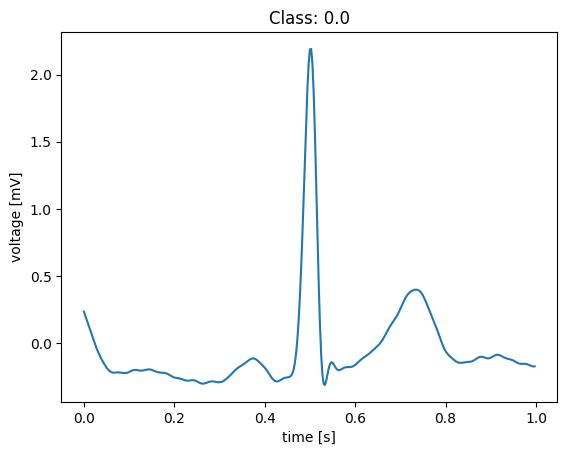

In [14]:
waveform, label = test_dataset.__getitem__(6)
# 5 is really good normal
# 14 is really good abnormal

ts = np.arange(len(waveform)) / 360
plt.plot(ts, waveform);
plt.xlabel('time [s]')
plt.ylabel('voltage [mV]');
plt.title(f'Class: {label[0]}')

In [15]:
with torch.no_grad():
    waveform_for_model = encoder.encode(waveform.unsqueeze(0))
    prediction, _, b_vals  = model(waveform_for_model, logging=True)
    prediction = int(prediction.sum(dim=(1,2)).item() > threshold)

print('Predicted Class: {}'.format(prediction)) 

Predicted Class: 0


In [16]:
b_0, b_1, b_2 = b_vals
b_0 = b_0.squeeze().numpy()
b_1 = b_1.squeeze().numpy()
b_2 = b_2.squeeze().numpy()

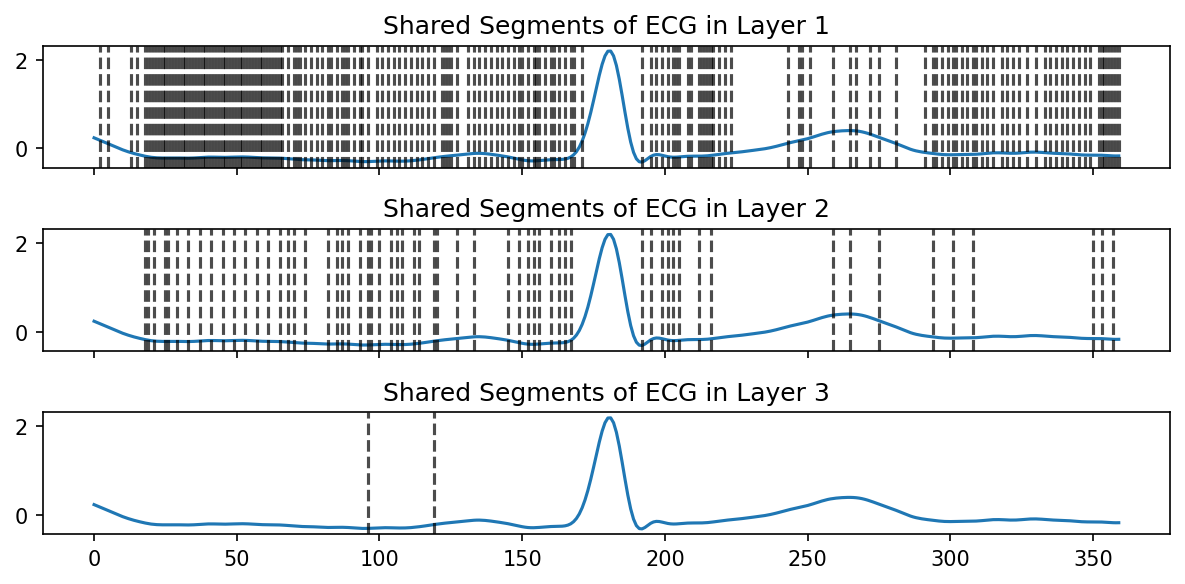

In [17]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(8, 4), gridspec_kw={'height_ratios': [3, 3, 3]}, dpi=150)

x = np.arange(len(b_0))
b_0_indeces = np.where(b_0 == 1)[0]
event_times = x[b_0_indeces]

ax1.plot(x, waveform)
for t in event_times:
    ax1.axvline(t, color='black', linestyle='--', alpha=0.7)

b_1_indeces = np.where(b_1 == 1)[0]
event_times = x[b_1_indeces]

ax2.plot(x, waveform)
for t in event_times:
    ax2.axvline(t, color='black', linestyle='--', alpha=0.7)

b_2_indeces = np.where(b_2 == 1)[0]
event_times = x[b_2_indeces]

ax3.plot(x, waveform)
for t in event_times:
    ax3.axvline(t, color='black', linestyle='--', alpha=0.7)


ax1.set_title('Shared Segments of ECG in Layer 1')
ax2.set_title('Shared Segments of ECG in Layer 2')
ax3.set_title('Shared Segments of ECG in Layer 3')

fig.tight_layout()


In [42]:
negative_waveform, label = test_dataset.__getitem__(6)

with torch.no_grad():
    negative_waveform_for_model = encoder.encode(negative_waveform.unsqueeze(0))
    negative_prediction, _, b_vals  = model(negative_waveform_for_model, logging=True)
    negative_prediction = int(negative_prediction.sum(dim=(1,2)).item() > threshold)

print('Predicted Class: {}, Real Class: {}'.format(negative_prediction, label[0])) 

neg_b_0, neg_b_1, neg_b_2 = b_vals
neg_b_0 = neg_b_0.squeeze().numpy()
neg_b_1 = neg_b_1.squeeze().numpy()
neg_b_2 = neg_b_2.squeeze().numpy()

positive_waveform, label = test_dataset.__getitem__(14)

with torch.no_grad():
    positive_waveform_for_model = encoder.encode(positive_waveform.unsqueeze(0))
    positive_prediction, _, b_vals  = model(positive_waveform_for_model, logging=True)
    positive_prediction = int(positive_prediction.sum(dim=(1,2)).item() > threshold)

print('Predicted Class: {}, Real Class: {}'.format(positive_prediction, label[0])) 

pos_b_0, pos_b_1, pos_b_2 = b_vals
pos_b_0 = pos_b_0.squeeze().numpy()
pos_b_1 = pos_b_1.squeeze().numpy()
pos_b_2 = pos_b_2.squeeze().numpy()

Predicted Class: 0, Real Class: 0.0
Predicted Class: 1, Real Class: 1.0


In [43]:
pos_example, label = test_dataset.__getitem__(6029)

for i, (_, label) in enumerate(test_dataset):
    print(i, label.max())

0 tensor(0.)
1 tensor(0.)
2 tensor(0.)
3 tensor(0.)
4 tensor(1.)
5 tensor(0.)
6 tensor(0.)
7 tensor(0.)
8 tensor(0.)
9 tensor(0.)
10 tensor(0.)
11 tensor(0.)
12 tensor(0.)
13 tensor(0.)
14 tensor(1.)
15 tensor(0.)
16 tensor(1.)
17 tensor(1.)
18 tensor(0.)
19 tensor(0.)
20 tensor(0.)
21 tensor(0.)
22 tensor(0.)
23 tensor(0.)
24 tensor(0.)
25 tensor(0.)
26 tensor(0.)
27 tensor(0.)
28 tensor(0.)
29 tensor(0.)
30 tensor(0.)
31 tensor(0.)
32 tensor(0.)
33 tensor(0.)
34 tensor(1.)
35 tensor(0.)
36 tensor(1.)
37 tensor(0.)
38 tensor(0.)
39 tensor(1.)
40 tensor(0.)
41 tensor(1.)
42 tensor(0.)
43 tensor(0.)
44 tensor(0.)
45 tensor(1.)
46 tensor(0.)
47 tensor(1.)
48 tensor(0.)
49 tensor(0.)
50 tensor(0.)
51 tensor(0.)
52 tensor(0.)
53 tensor(0.)
54 tensor(0.)
55 tensor(1.)
56 tensor(0.)
57 tensor(0.)
58 tensor(0.)
59 tensor(0.)
60 tensor(0.)
61 tensor(1.)
62 tensor(0.)
63 tensor(0.)
64 tensor(0.)
65 tensor(0.)
66 tensor(1.)
67 tensor(0.)
68 tensor(1.)
69 tensor(0.)
70 tensor(0.)
71 tensor(0.)
72

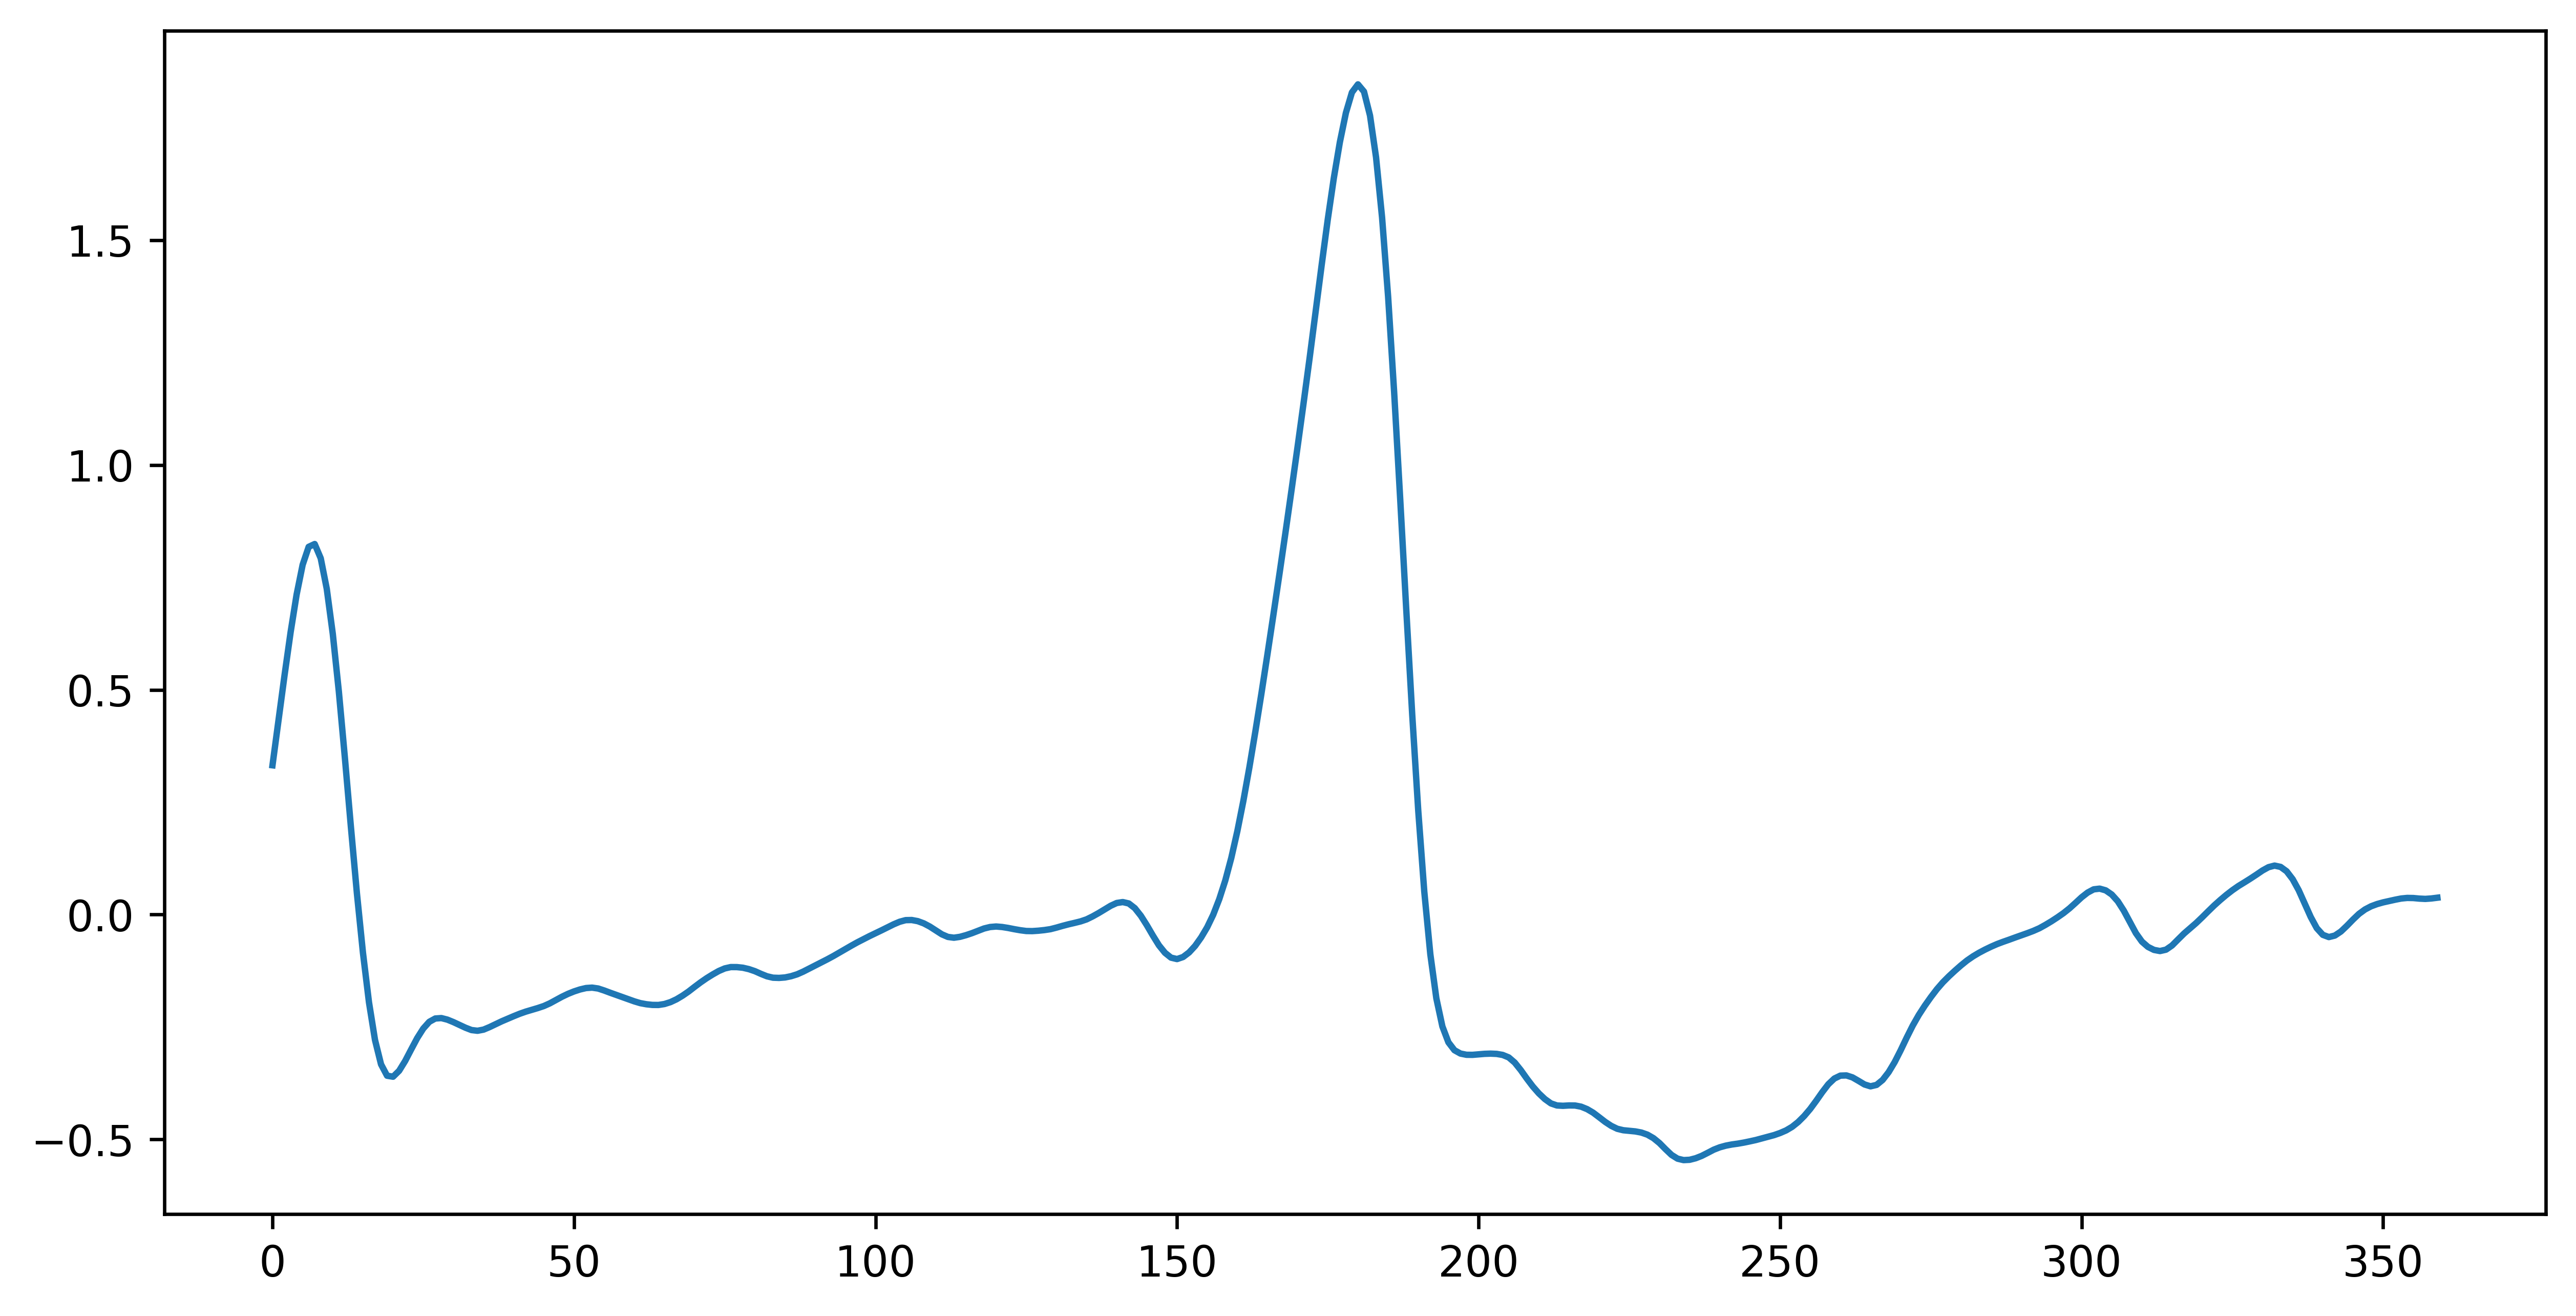

In [44]:
fig, axes = plt.subplots(1, 1, figsize=(10, 5), dpi=600)

# x axes
x_pos = np.arange(len(pos_example))

axes.plot(x_pos, pos_example)

plt.show()


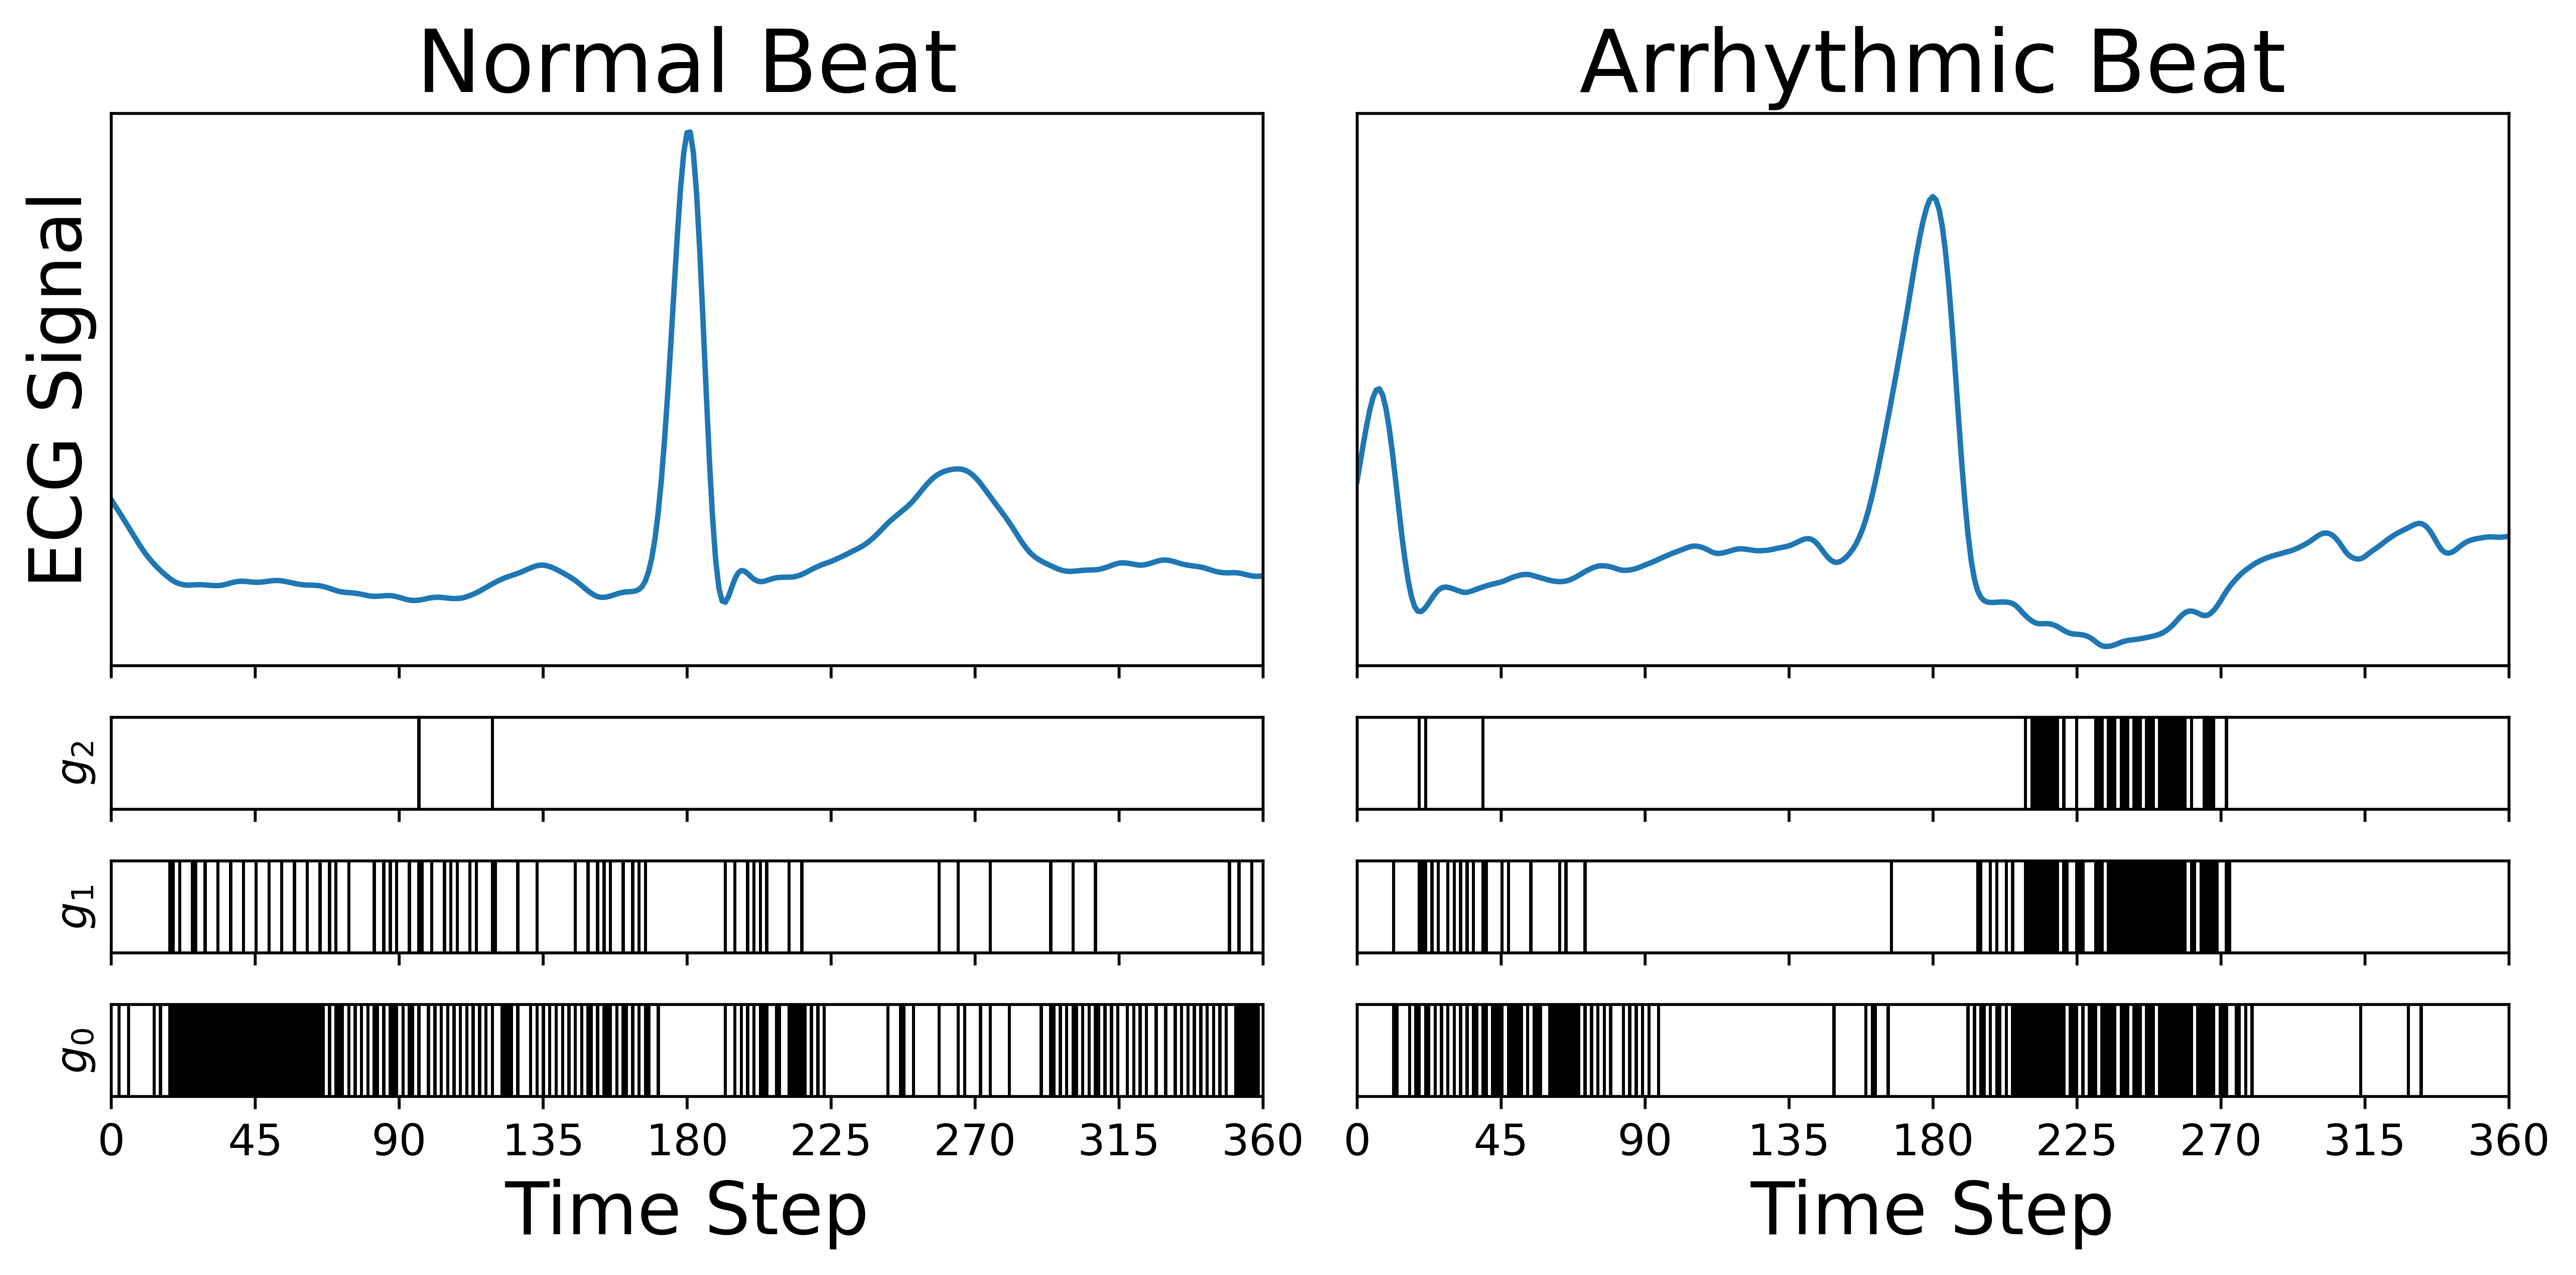

In [41]:
fig, axes = plt.subplots(
    4, 2,
    sharex='col',
    figsize=(10, 5),
    gridspec_kw={'height_ratios': [3, 0.5, 0.5, 0.5]},
    dpi=600,
)

# x axes
x_neg = np.arange(len(neg_b_0))
x_pos = np.arange(len(pos_b_0))

# -------------------
# LEFT COLUMN: Negative
# -------------------
axes[0, 0].plot(x_neg, negative_waveform, )
axes[1, 0].imshow(neg_b_2[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)
axes[2, 0].imshow(neg_b_1[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)
axes[3, 0].imshow(neg_b_0[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)

# -------------------
# RIGHT COLUMN: Positive
# -------------------
axes[0, 1].plot(x_pos, positive_waveform)
axes[1, 1].imshow(pos_b_2[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)
axes[2, 1].imshow(pos_b_1[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)
axes[3, 1].imshow(pos_b_0[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)

# -------------------
# Formatting
# -------------------
for col in range(2):
    for row in range(4):
        axes[row, col].set_yticks([])
        axes[row, col].set_xlim(0,max(len(neg_b_0), len(pos_b_0)) - 1)
        axes[row, col].set_xticks([0, 45, 90, 135, 180, 225, 270, 315, 360])
        axes[row, col].tick_params(axis='x', labelsize=12)

y_min = min(negative_waveform.min(), positive_waveform.min()) - 0.1
y_max = max(negative_waveform.max(), positive_waveform.max()) + 0.1

axes[0, 0].set_ylim(y_min, y_max)
axes[0, 1].set_ylim(y_min, y_max)

# Row labels
axes[0, 0].set_ylabel('ECG Signal', fontsize=20,)
axes[1, 0].set_ylabel('$g_2$', fontsize=12,)
axes[2, 0].set_ylabel('$g_1$', fontsize=12,)
axes[3, 0].set_ylabel('$g_0$', fontsize=12,)

# Column titles
axes[0, 0].set_title('Normal Beat', fontsize=24, )
axes[0, 1].set_title('Arrhythmic Beat', fontsize=24, )

# X labels
axes[3, 0].set_xlabel('Time Step', fontsize=20)
axes[3, 1].set_xlabel('Time Step', fontsize=20)

plt.tight_layout()
plt.savefig("../figures/gate_visualization_transparent.png", dpi=600, bbox_inches="tight", transparent=True)

plt.show()


In [139]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

def train_pca_lda(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("clf", LinearDiscriminantAnalysis())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

def train_pca_logreg(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("clf", LogisticRegression())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

def train_logreg(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

In [14]:
train_X = []
train_y = []

for i in range(len(train_dataset)):
    w, l = train_dataset.__getitem__(i)
    train_X.append(w)
    train_y.append(l[0])

train_X = np.stack(train_X)
train_y = np.stack(train_y)

test_X = []
test_y = []

for i in range(len(test_dataset)):
    w, l = test_dataset.__getitem__(i)
    test_X.append(w)
    test_y.append(l[0])

test_X = np.stack(test_X)
test_y = np.stack(test_y)


In [15]:
train_logreg(train_X, train_y, test_X, test_y, n_components=100)

Accuracy: 0.7328471992045078
              precision    recall  f1-score   support

         0.0       0.85      0.76      0.80      4347
         1.0       0.52      0.65      0.58      1687

    accuracy                           0.73      6034
   macro avg       0.68      0.71      0.69      6034
weighted avg       0.76      0.73      0.74      6034



/Users/rahul/anaconda3/envs/arr/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work